In [37]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal


# Sorry for the typos in advance

print("Installations Working!")

Installations Working!


# Data Setup

In [38]:
# Parameter Definitions

class_1_prior = .3
class_2_prior = .3
class_3_prior = .4

# Set Random Seed
rng = np.random.default_rng(1)

dist_1_mu = [1, 1, 1]
dist_2_mu = [1, -1, -1]
dist_3_mu = [-1, 1, -1]
dist_4_mu = [-1, -1, 1]


# Quick verification of mean equidistance
mu_list = [dist_1_mu, dist_2_mu, dist_3_mu, dist_4_mu]


dist_1_cov = [[2,   -1.5, .5],
              [-1.5, 2, 1],
              [.5, 1, 5]]

dist_2_cov = [[1,   -.2, -.5],
              [-.2, 2, .5],
              [-.5, .5, 1.5]]

dist_3_cov = [[1, .1, .5],
              [.1, 1.5, 1],
              [.5, 1, 1.5]]

dist_4_cov = [[2, .1, .5],
              [.1, 2, .1],
              [.5, .1, .5]]

cov_list = [dist_1_cov, dist_2_cov, dist_3_cov, dist_4_cov]

# average standard deviation across all components
all_stds = [np.sqrt(np.diag(np.array(C))) for C in cov_list]
avg_std = np.mean(all_stds)
print(f"Average std: {avg_std:.4f}")

# distance / avg_std for every pair
for i in range(len(mu_list)):
    for j in range(i + 1, len(mu_list)):
        d = np.linalg.norm(np.array(mu_list[i]) - np.array(mu_list[j]))
        print(f"mu_{i+1} to mu_{j+1}: distance = {d:.3f}, ratio = {d / avg_std:.2f}")


L = (rng.random(10000) < .3).astype(int)   # 1 with prob 0.65, else 0
n1 = np.sum(L == 1)

n0 = np.sum(L == 0)
L = (rng.random(n0) < (.3/.7)).astype(int)
n2 = np.sum(L == 1)
n3 = np.sum(L == 0)

dist_1 = rng.multivariate_normal(dist_1_mu, dist_1_cov, size=n1)
dist_2 = rng.multivariate_normal(dist_2_mu, dist_2_cov, size=n2)
dist_3 = rng.multivariate_normal(dist_3_mu, dist_3_cov, size=int(n3/2))
dist_4 = rng.multivariate_normal(dist_4_mu, dist_4_cov, size=int(n3/2)+1)

X_dist = np.vstack([dist_1, dist_2, dist_3, dist_4])
L = np.concatenate([np.full(n1, 1), np.full(n2, 2), np.full(n3, 3)])
# Verification

print(f"Dist: X_dist | Shape: {X_dist.shape}")
print(f"Mean: {np.mean(X_dist)} | {np.mean(X_dist[L == 1], axis=0)} | {np.mean(X_dist[L == 2], axis=0)} | {np.mean(X_dist[L == 3], axis=0)}")
print(f"Labels: {np.mean(L)} | Shape: {L.shape}")



print(f"Counts-- N1: {n1} | N2: {n2} | N3: {n3}")

Average std: 1.3074
mu_1 to mu_2: distance = 2.828, ratio = 2.16
mu_1 to mu_3: distance = 2.828, ratio = 2.16
mu_1 to mu_4: distance = 2.828, ratio = 2.16
mu_2 to mu_3: distance = 2.828, ratio = 2.16
mu_2 to mu_4: distance = 2.828, ratio = 2.16
mu_3 to mu_4: distance = 2.828, ratio = 2.16
Dist: X_dist | Shape: (10000, 3)
Mean: 0.06623971052317923 | [1.004787   0.99245048 0.97059489] | [ 1.03779876 -0.98037188 -1.02169687] | [-1.00088136e+00  3.46699145e-03  7.80014375e-04]
Labels: 2.0937 | Shape: (10000,)
Counts-- N1: 2990 | N2: 3083 | N3: 3927


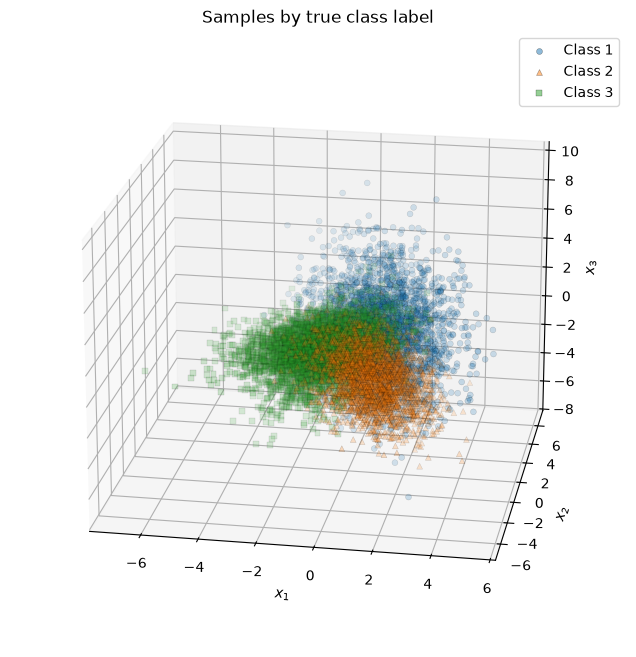

In [39]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection='3d')
markers = {1: 'o', 2: '^', 3: 's'}                         # circle, triangle, square
colors  = {1: 'tab:blue', 2: 'tab:orange', 3: 'tab:green'}

for k in [1, 2, 3]:
    pts = X_dist[L == k]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
               marker=markers[k], color=colors[k],
               s=18, alpha=0.5, edgecolors='k', linewidths=0.3,
               label=f"Class {k}")
ax.view_init(elev=20, azim=280)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.set_title("Samples by true class label")
ax.legend()
plt.show()

# Part A.2


In [40]:
# ERM Classifier


def g(mu, C):
    return multivariate_normal(mu, C).pdf(X_dist)

scores = np.stack([
    g(dist_1_mu, dist_1_cov) * class_1_prior,
    g(dist_2_mu, dist_2_cov) * class_2_prior,
    (0.5 * g(dist_3_mu, dist_3_cov) + 0.5 * g(dist_4_mu, dist_4_cov)) * class_3_prior,
], axis=1)

D = np.argmax(scores, axis=1) + 1     # decisions, 1/2/3


scores.shape

print(f"Accuracy: {np.mean(D == L)}")

Accuracy: 0.7871


In [41]:
Lambda = 1 - np.eye(3)          # 0-1 loss -> gives the same result as MAP
risks = scores @ Lambda.T        # shape (10000, 3): risk of each decision
D_erm = np.argmin(risks, axis=1) + 1

D_erm
print(f"Accuracy: {np.mean(D_erm == L)}")

Accuracy: 0.7871


In [42]:
conf = np.zeros((3, 3))
for i in [1, 2, 3]:
    for j in [1, 2, 3]:
        conf[i-1, j-1] = np.mean(D[L == j] == i)    # P(D=i | L=j)
print(np.round(conf, 3))

[[0.714 0.108 0.091]
 [0.155 0.779 0.06 ]
 [0.131 0.113 0.849]]


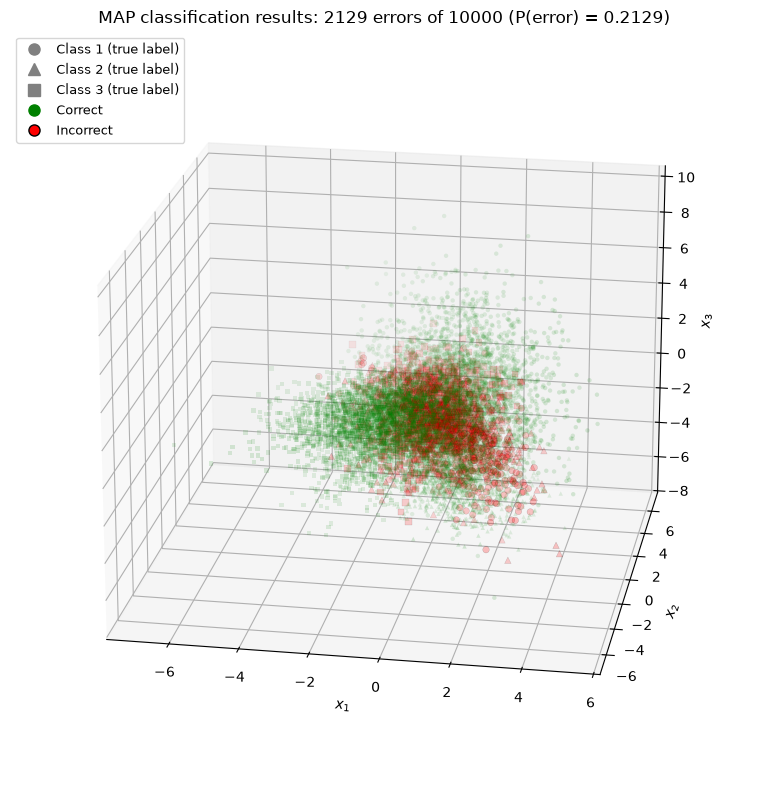

In [46]:
from matplotlib.lines import Line2D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

markers = {1: 'o', 2: '^', 3: 's'}
names   = {1: "Class 1", 2: "Class 2", 3: "Class 3"}

# Correct points first (faint), then incorrect points on top (bold)
for k in [1, 2, 3]:
    correct = (L == k) & (D == k)
    ax.scatter(*X_dist[correct].T, marker=markers[k], color='green',
               s=10, alpha=0.4, linewidths=0)
for k in [1, 2, 3]:
    wrong = (L == k) & (D != k)
    ax.scatter(*X_dist[wrong].T, marker=markers[k], color='red',
               s=22, alpha=0.5, edgecolors='k', linewidths=0.3)

# Legend: shapes = true class, colors = correct / incorrect
shape_handles = [Line2D([], [], marker=markers[k], color='gray', linestyle='',
                        markersize=8, label=f"{names[k]} (true label)")
                 for k in [1, 2, 3]]
color_handles = [Line2D([], [], marker='o', color='green', linestyle='',
                        markersize=8, label="Correct"),
                 Line2D([], [], marker='o', color='red', markeredgecolor='k',
                        linestyle='', markersize=8, label="Incorrect")]
ax.legend(handles=shape_handles + color_handles, loc='upper left', fontsize=9)

# Title with the overall error
n_wrong = np.sum(D != L)
ax.set_title(f"MAP classification results: {n_wrong} errors of {len(L)} "
             f"(P(error) = {n_wrong / len(L):.4f})")

ax.view_init(elev=20, azim=280)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
plt.tight_layout()
plt.show()

# Part B

In [47]:
loss_matrices = {
    "0-1 loss (MAP)":  1 - np.eye(3),
    r"$\Lambda_{10}$":  np.array([[0, 1, 10],  [1, 0, 10],  [1, 1, 0]]),
    r"$\Lambda_{100}$": np.array([[0, 1, 100], [1, 0, 100], [1, 1, 0]]),
}

results = {}
for name, Lam in loss_matrices.items():
    risks = scores @ Lam.T
    D = np.argmin(risks, axis=1) + 1

    conf = np.zeros((3, 3))
    for i in [1, 2, 3]:
        for j in [1, 2, 3]:
            conf[i-1, j-1] = np.mean(D[L == j] == i)       # P(D=i | L=j)

    per_class = [np.mean(D[L == k] != k) for k in [1, 2, 3]]
    n_err = np.sum(D != L)
    risk = np.mean(Lam[D - 1, L - 1])
    results[name] = (per_class, n_err, n_err / len(L), risk)

    print(f"===== {name} =====")
    print("Confusion matrix P(D=i | L=j):")
    print(np.round(conf, 3))
    print(f"Accuracy: {np.mean(D == L):.4f}\n")

# Summary table
print(f"{'Loss matrix':<18}{'Class 1':>9}{'Class 2':>9}{'Class 3':>9}"
      f"{'Errors':>9}{'P(error)':>10}{'Exp. risk':>11}")
for name, (pc, n_err, p_err, risk) in results.items():
    label = name.replace("$", "").replace("\\Lambda_", "Lambda_").replace("{", "").replace("}", "")
    print(f"{label:<18}{pc[0]:>9.3f}{pc[1]:>9.3f}{pc[2]:>9.3f}"
          f"{n_err:>9}{p_err:>10.3f}{risk:>11.3f}")

# LaTeX rows for the table
print("\nLaTeX rows:")
for name, (pc, n_err, p_err, risk) in results.items():
    cells = " & ".join(f"{e:.3f}" for e in pc)
    print(f"{name:<18} & {cells} & {n_err} & {p_err:.3f} & {risk:.3f} \\\\")



===== 0-1 loss (MAP) =====
Confusion matrix P(D=i | L=j):
[[0.714 0.108 0.091]
 [0.155 0.779 0.06 ]
 [0.131 0.113 0.849]]
Accuracy: 0.7871

===== $\Lambda_{10}$ =====
Confusion matrix P(D=i | L=j):
[[0.405 0.04  0.007]
 [0.11  0.608 0.007]
 [0.484 0.352 0.985]]
Accuracy: 0.6957

===== $\Lambda_{100}$ =====
Confusion matrix P(D=i | L=j):
[[0.204 0.016 0.   ]
 [0.056 0.381 0.001]
 [0.74  0.603 0.999]]
Accuracy: 0.5711

Loss matrix         Class 1  Class 2  Class 3   Errors  P(error)  Exp. risk
0-1 loss (MAP)        0.286    0.221    0.151     2129     0.213      0.213
Lambda_10             0.595    0.392    0.015     3043     0.304      0.356
Lambda_100            0.796    0.619    0.001     4289     0.429      0.449

LaTeX rows:
0-1 loss (MAP)     & 0.286 & 0.221 & 0.151 & 2129 & 0.213 & 0.213 \\
$\Lambda_{10}$     & 0.595 & 0.392 & 0.015 & 3043 & 0.304 & 0.356 \\
$\Lambda_{100}$    & 0.796 & 0.619 & 0.001 & 4289 & 0.429 & 0.449 \\


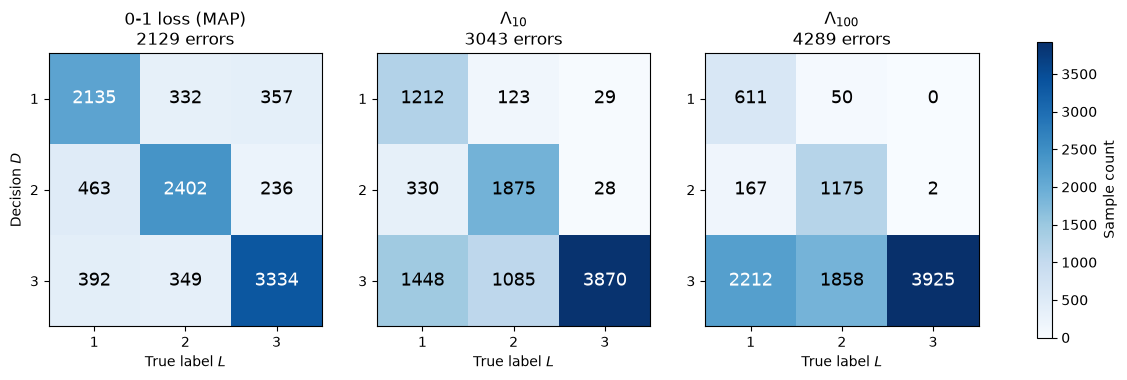

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# Compute all three count matrices first so they can share one color scale
count_mats = {}
for name, Lam in loss_matrices.items():
    D = np.argmin(scores @ Lam.T, axis=1) + 1
    counts = np.zeros((3, 3), dtype=int)
    for i in [1, 2, 3]:
        for j in [1, 2, 3]:
            counts[i-1, j-1] = np.sum((D == i) & (L == j))
    count_mats[name] = counts

vmax = max(c.max() for c in count_mats.values())

for ax, (name, counts) in zip(axes, count_mats.items()):
    im = ax.imshow(counts, cmap="Blues", vmin=0, vmax=vmax)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{counts[i, j]}", ha="center", va="center", fontsize=13,
                    color="white" if counts[i, j] > 0.5 * vmax else "black")
    ax.set_xticks(range(3), labels=[1, 2, 3])
    ax.set_yticks(range(3), labels=[1, 2, 3])
    ax.set_xlabel("True label $L$")
    n_err = counts.sum() - np.trace(counts)
    ax.set_title(f"{name}\n{n_err} errors")
axes[0].set_ylabel("Decision $D$")

fig.colorbar(im, ax=axes, shrink=0.8, label="Sample count")
plt.savefig("q2_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()